# Teste A/B bem feito: o que decide se o resultado é confiável

**Situação:** um e-commerce quer testar um checkout novo. A conversão atual é de 3% e chegam cerca de 4 mil visitantes por dia, divididos meio a meio entre o checkout atual (A) e o novo (B).

**Perguntas que este notebook responde:**
1. Quantos visitantes são necessários, e por quanto tempo o teste precisa rodar?
2. O que acontece se o time olhar o resultado todo dia e parar quando "der significativo"?
3. Como olhar o resultado antes do fim sem inflar o falso positivo?
4. E se o resultado for aberto por 20 segmentos?
5. Dá para precisar de menos gente usando o comportamento anterior ao teste (CUPED)?
6. Como saber se a própria divisão do tráfego deu errado?

**Dados:** simulados, e isso é proposital. Num teste A/B real nunca se sabe o efeito verdadeiro; na simulação, sim. Por isso dá para medir com exatidão quanto cada erro custa.

In [1]:
import sys
import warnings

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

sys.path.insert(0, "../src")
from causal.ab import (correcao_bh, correcao_holm, cuped, diferenca_medias, fronteira_obrien_fleming,
                       poder_simulado, simular_espiadas, tamanho_amostra_proporcoes,
                       taxa_falso_positivo_espiando, verificar_srm)
from causal.estilo import COR, aplicar, br, fonte, subtitulo

warnings.filterwarnings("ignore")
aplicar()
FONTE = "Dados simulados · elaboração: Cézar Bento"
FIG = "../figures/"

P_BASE = 0.03          # conversão atual
VISITAS_DIA = 2_000    # por grupo
EFEITO = 0.10          # menor melhora que vale a pena detectar: +10% relativo (3,0% → 3,3%)

## 1. Quantos visitantes são necessários?

O tamanho da amostra depende de três escolhas que são de negócio, não de estatística: a **menor melhora que vale a pena detectar** (efeito mínimo detectável), o risco aceito de um falso positivo (α = 5%) e a chance de detectar a melhora se ela existir (poder = 80%).

In [2]:
n = tamanho_amostra_proporcoes(P_BASE, EFEITO)
dias = int(np.ceil(n / VISITAS_DIA))
print(f"Para detectar 3,0% → 3,3%: {br(n)} visitantes por grupo, cerca de {dias} dias")
print(f"Conferência por simulação: poder de {poder_simulado(P_BASE, EFEITO, n):.1%} com esse tamanho")

efeitos = np.array([0.05, 0.075, 0.10, 0.15, 0.20, 0.30])
necessarios = np.array([tamanho_amostra_proporcoes(P_BASE, e) for e in efeitos])
for e, m in zip(efeitos, necessarios):
    print(f"  efeito de {e:>5.1%}: {br(m):>8} por grupo · {m / VISITAS_DIA:5.0f} dias")

Para detectar 3,0% → 3,3%: 53.211 visitantes por grupo, cerca de 27 dias
Conferência por simulação: poder de 80.1% com esse tamanho
  efeito de  5.0%:  207.938 por grupo ·   104 dias
  efeito de  7.5%:   93.508 por grupo ·    47 dias
  efeito de 10.0%:   53.211 por grupo ·    27 dias
  efeito de 15.0%:   24.193 por grupo ·    12 dias
  efeito de 20.0%:   13.914 por grupo ·     7 dias
  efeito de 30.0%:    6.455 por grupo ·     3 dias


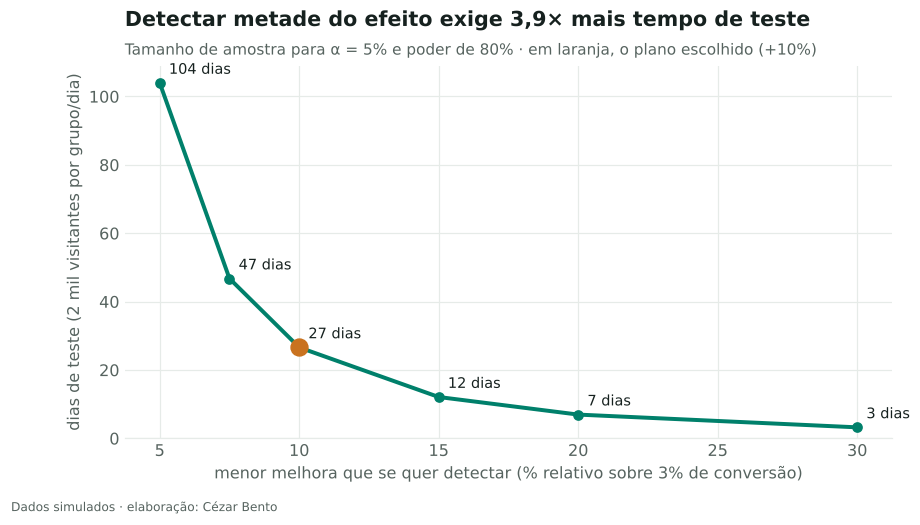

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.plot(efeitos * 100, necessarios / VISITAS_DIA, color=COR["principal"], lw=2.6, marker="o")
for e, m in zip(efeitos, necessarios):
    ax.annotate(f"{m / VISITAS_DIA:.0f} dias", (e * 100, m / VISITAS_DIA), xytext=(6, 6), textcoords="offset points",
                fontsize=9.5, color=COR["texto"])
ax.plot(EFEITO * 100, n / VISITAS_DIA, marker="o", ms=11, color=COR["destaque"], zorder=3)
ax.set_xlabel("menor melhora que se quer detectar (% relativo sobre 3% de conversão)")
ax.set_ylabel("dias de teste (2 mil visitantes por grupo/dia)")
ax.set_ylim(0, None)
razao = necessarios[0] / necessarios[2]
ax.set_title(f"Detectar metade do efeito exige {br(razao, 1)}× mais tempo de teste")
subtitulo(ax, "Tamanho de amostra para α = 5% e poder de 80% · em laranja, o plano escolhido (+10%)")
fonte(fig, FONTE)
fig.savefig(FIG + "01_tamanho_amostra.png")

**Leitura:** o tempo de teste cresce com o inverso do quadrado do efeito. Querer detectar +5% em vez de +10% custa quase 4 vezes mais tempo. A conversa com o negócio deve ser "qual a menor melhora que muda a decisão?", e não "quanto tempo dá para rodar?".

## 2. O erro de espiar o resultado

O plano arredondado é de 4 semanas (28 dias), mas o time abre o painel todo dia e para no primeiro dia em que p < 0,05. Para medir o estrago, simulo 5 mil **testes A/A**, em que A e B são idênticos e qualquer "vencedor" é um falso positivo.

In [4]:
DIAS = 28
z_aa = simular_espiadas(P_BASE, VISITAS_DIA, DIAS, simulacoes=5_000, semente=0)
frequencias = {"só no fim": [DIAS], "semanal (4×)": [7, 14, 21, 28], "a cada 2 dias": list(range(2, DIAS + 1, 2)),
               "todo dia": list(range(1, DIAS + 1))}
taxas = {nome: taxa_falso_positivo_espiando(z_aa, olhados) for nome, olhados in frequencias.items()}
for nome, t in taxas.items():
    print(f"{nome:>14}: {t:.1%} de falsos positivos")

     só no fim: 5.0% de falsos positivos
  semanal (4×): 12.5% de falsos positivos
 a cada 2 dias: 22.1% de falsos positivos
      todo dia: 27.3% de falsos positivos


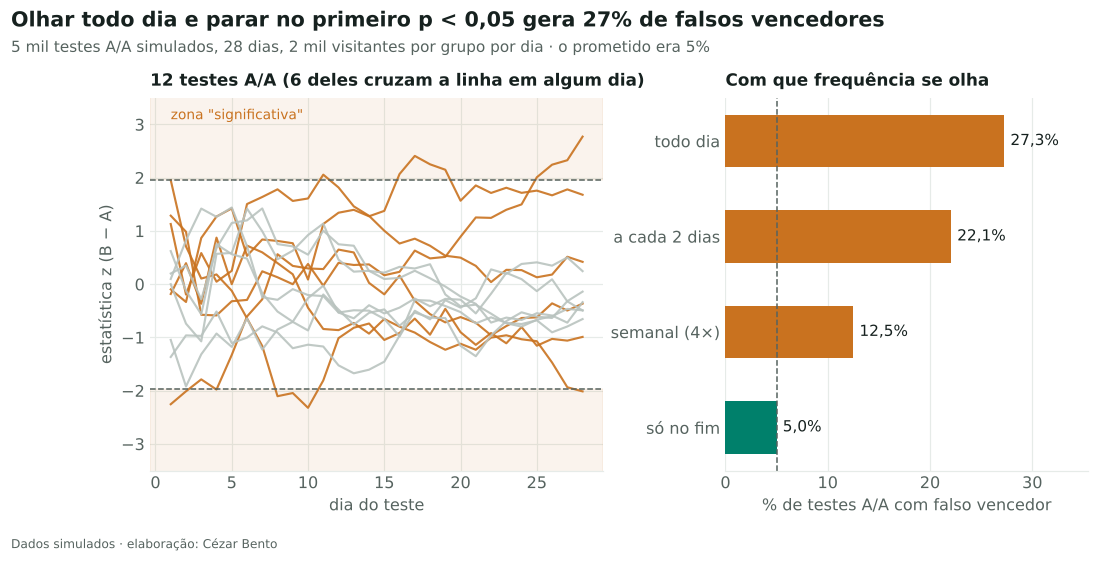

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw={"width_ratios": [1.25, 1], "wspace": 0.3})
ax = axes[0]
dias_eixo = np.arange(1, DIAS + 1)
cruzou = (np.abs(z_aa) > 1.96).any(axis=1)
exemplos = np.r_[np.where(cruzou)[0][:6], np.where(~cruzou)[0][:6]]
for i in exemplos:
    ax.plot(dias_eixo, z_aa[i], color=COR["destaque"] if cruzou[i] else COR["contexto"], lw=1.4, alpha=0.9)
ax.axhspan(1.96, 4, color=COR["destaque"], alpha=0.08); ax.axhspan(-4, -1.96, color=COR["destaque"], alpha=0.08)
ax.axhline(1.96, color=COR["texto2"], lw=1, ls="--"); ax.axhline(-1.96, color=COR["texto2"], lw=1, ls="--")
ax.set_ylim(-3.5, 3.5); ax.set_xlabel("dia do teste"); ax.set_ylabel("estatística z (B − A)")
ax.set_title("12 testes A/A (6 deles cruzam a linha em algum dia)", fontsize=11, pad=8)
ax.text(1, 3.1, "zona \"significativa\"", fontsize=9, color=COR["destaque"])

ax = axes[1]
nomes = list(taxas)
ax.barh(nomes, [taxas[k] * 100 for k in nomes], color=[COR["principal"]] + [COR["destaque"]] * 3, height=0.55)
for i, k in enumerate(nomes):
    ax.text(taxas[k] * 100 + 0.6, i, f"{br(taxas[k] * 100, 1)}%", va="center", fontsize=10, color=COR["texto"])
ax.axvline(5, color=COR["texto2"], lw=1, ls="--")
ax.set_xlim(0, max(taxas.values()) * 130); ax.grid(axis="y", visible=False)
ax.set_xlabel("% de testes A/A com falso vencedor"); ax.set_title("Com que frequência se olha", fontsize=11, pad=8)
fig.suptitle(f"Olhar todo dia e parar no primeiro p < 0,05 gera {br(taxas['todo dia'] * 100)}% de falsos vencedores",
             x=0.01, ha="left", fontsize=13.5, fontweight="bold", color=COR["texto"], y=1.06)
fig.text(0.01, 0.975, "5 mil testes A/A simulados, 28 dias, 2 mil visitantes por grupo por dia · o prometido era 5%",
         fontsize=10, color=COR["texto2"])
fonte(fig, FONTE, y=-0.03)
fig.savefig(FIG + "02_espiar.png")

**Leitura:** o α de 5% só vale para **uma** olhada, no fim. Cada olhada extra é uma nova chance de o ruído cruzar a linha, e o teste que "deu certo no dia 9" muitas vezes é só ruído. Na prática, isso explica boa parte dos ganhos de A/B que somem quando a mudança vai para produção.

## 3. Como olhar antes sem inflar o erro: limites de O'Brien-Fleming

Às vezes é preciso olhar antes (um efeito negativo grande, por exemplo, deveria parar o teste). A solução é decidir **antes** quantas vezes olhar e usar limites mais exigentes no começo. Os limites abaixo são calibrados por simulação para que o erro total, somando as 4 olhadas, continue em 5%.

In [6]:
OLHADAS = [7, 14, 21, 28]
limites = fronteira_obrien_fleming(z_aa, OLHADAS)
print("Limites de |z| por semana:", ", ".join(f"{br(l, 2)}" for l in limites))
print(f"Falso positivo com os limites: {taxa_falso_positivo_espiando(z_aa, OLHADAS, limites):.1%}")

# Com efeito real de +10%: quanto poder se perde e quanto tempo se ganha?
z_ef = simular_espiadas(P_BASE, VISITAS_DIA, DIAS, simulacoes=5_000, efeito_relativo=EFEITO, semente=1)
poder_fixo = taxa_falso_positivo_espiando(z_ef, [DIAS])
cruza = np.abs(z_ef[:, np.array(OLHADAS) - 1]) > limites
poder_seq = cruza.any(axis=1).mean()
parada = np.where(cruza.any(axis=1), np.array(OLHADAS)[cruza.argmax(axis=1)], DIAS)
print(f"Poder com uma olhada no fim: {poder_fixo:.1%} · com O'Brien-Fleming: {poder_seq:.1%}")
print(f"Duração média com efeito real: {parada.mean():.1f} dias (contra {DIAS} fixos)")
print("Em que semana os testes vencedores param:",
      {f"semana {i + 1}": f"{(parada[cruza.any(axis=1)] == d).mean():.0%}" for i, d in enumerate(OLHADAS)})

Limites de |z| por semana: 4,03, 2,85, 2,33, 2,01
Falso positivo com os limites: 5.0%
Poder com uma olhada no fim: 82.7% · com O'Brien-Fleming: 81.8%
Duração média com efeito real: 22.4 dias (contra 28 fixos)
Em que semana os testes vencedores param: {'semana 1': '0%', 'semana 2': '26%', 'semana 3': '45%', 'semana 4': '28%'}


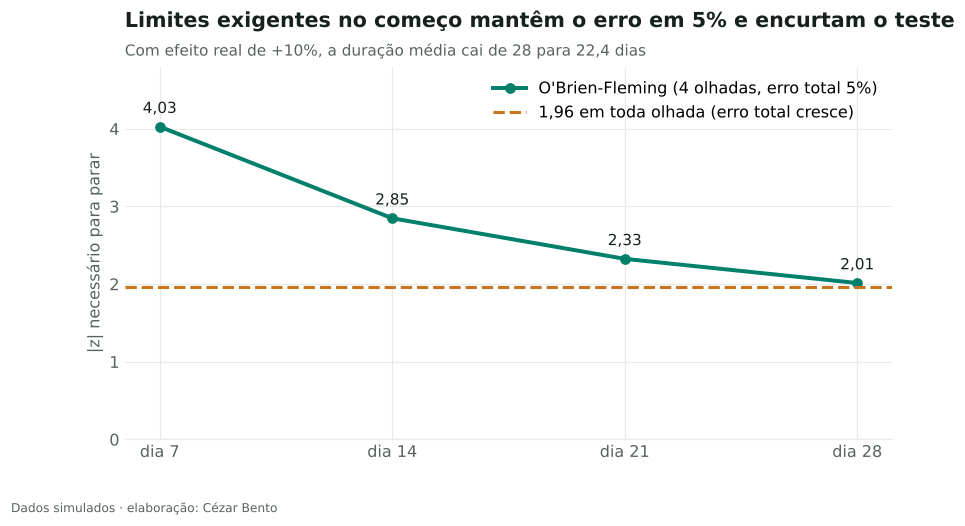

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.4))
x = np.array(OLHADAS)
ax.plot(x, limites, color=COR["principal"], lw=2.6, marker="o", label="O'Brien-Fleming (4 olhadas, erro total 5%)")
ax.axhline(1.96, color=COR["destaque"], lw=2, ls="--", label="1,96 em toda olhada (erro total cresce)")
for xi, l in zip(x, limites):
    ax.annotate(br(l, 2), (xi, l), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=10, color=COR["texto"])
ax.set_xticks(x, [f"dia {d}" for d in x]); ax.set_ylim(0, 4.8); ax.set_ylabel("|z| necessário para parar")
ax.legend(loc="upper right")
ax.set_title("Limites exigentes no começo mantêm o erro em 5% e encurtam o teste")
subtitulo(ax, f"Com efeito real de +10%, a duração média cai de {DIAS} para {br(parada.mean(), 1)} dias")
fonte(fig, FONTE)
fig.savefig(FIG + "03_obrien_fleming.png")

## 4. Abrir o resultado por segmento

Depois do teste, é comum abrir o resultado por canal, região, dispositivo, faixa de idade... Com 20 segmentos e **nenhum efeito real**, quantas vezes aparece pelo menos um segmento "significativo"?

In [8]:
rng = np.random.default_rng(2)
SEGMENTOS, SIMULACOES = 20, 5_000
# Sob a hipótese nula, os p-valores de cada segmento são uniformes entre 0 e 1
p_nulos = rng.uniform(size=(SIMULACOES, SEGMENTOS))
achou = {
    "Sem correção": (p_nulos < 0.05).any(axis=1).mean(),
    "Holm": (np.apply_along_axis(correcao_holm, 1, p_nulos) < 0.05).any(axis=1).mean(),
    "Benjamini-Hochberg": (np.apply_along_axis(correcao_bh, 1, p_nulos) < 0.05).any(axis=1).mean(),
}
for k, v in achou.items():
    print(f"{k:>19}: {v:.1%} dos testes com ao menos um segmento 'significativo'")
print(f"Teoria sem correção: 1 − 0,95^20 = {1 - 0.95 ** 20:.1%}")

       Sem correção: 64.8% dos testes com ao menos um segmento 'significativo'
               Holm: 4.7% dos testes com ao menos um segmento 'significativo'
 Benjamini-Hochberg: 4.8% dos testes com ao menos um segmento 'significativo'
Teoria sem correção: 1 − 0,95^20 = 64.2%


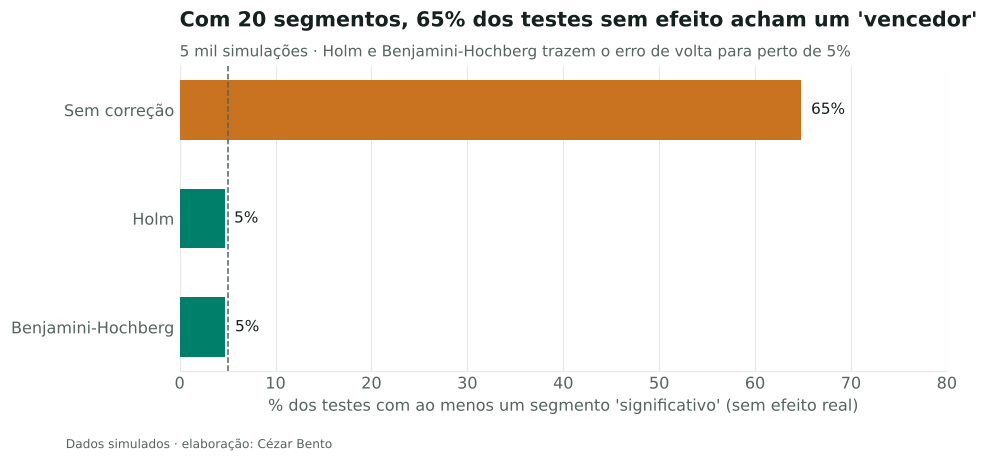

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.6))
nomes = list(achou)
ax.barh(nomes[::-1], [achou[k] * 100 for k in nomes[::-1]], color=[COR["principal"], COR["principal"], COR["destaque"]], height=0.55)
for i, k in enumerate(nomes[::-1]):
    ax.text(achou[k] * 100 + 1, i, f"{br(achou[k] * 100)}%", va="center", fontsize=10, color=COR["texto"])
ax.axvline(5, color=COR["texto2"], lw=1, ls="--"); ax.set_xlim(0, 80); ax.grid(axis="y", visible=False)
ax.set_xlabel("% dos testes com ao menos um segmento 'significativo' (sem efeito real)")
ax.set_title(f"Com 20 segmentos, {br(achou['Sem correção'] * 100)}% dos testes sem efeito acham um 'vencedor'")
subtitulo(ax, "5 mil simulações · Holm e Benjamini-Hochberg trazem o erro de volta para perto de 5%")
fonte(fig, FONTE, y=-0.06)
fig.savefig(FIG + "04_multiplas_comparacoes.png")

**Leitura:** segmento significativo encontrado depois do teste é **hipótese** para um próximo teste, não resultado. Holm controla a chance de qualquer falso positivo (bom para decisões de produto); Benjamini-Hochberg controla a fração de falsos entre os achados (bom para triagem exploratória).

## 5. CUPED: menos gente para a mesma precisão

Para métricas contínuas, como receita por visitante, boa parte da variação vem de quem o cliente já era antes do teste. O CUPED usa o gasto **anterior** ao teste para tirar essa parte previsível. Como o período anterior não pode ter sido afetado pelo teste, o efeito estimado continua sem viés.

In [10]:
def simular_receita(n, efeito, rng, rho=0.7):
    """Receita no teste correlacionada com a receita dos 30 dias anteriores (log-normal, como gasto real)."""
    pre = rng.lognormal(3.0, 0.8, n)
    ruido = rng.lognormal(3.0, 0.8, n)
    # Mistura que dá correlação próxima de rho entre o antes e o durante
    durante = rho * pre + np.sqrt(1 - rho ** 2) * ruido
    return pre, durante + efeito

rng = np.random.default_rng(3)
N, EFEITO_REAIS = 5_000, 1.0  # 5 mil por grupo; o checkout novo aumenta a receita em R$ 1 por visitante
est_simples, est_cuped, cobre_simples, cobre_cuped = [], [], [], []
for _ in range(2_000):
    pre_a, y_a = simular_receita(N, 0.0, rng)
    pre_b, y_b = simular_receita(N, EFEITO_REAIS, rng)
    d, lo, hi = diferenca_medias(y_a, y_b)
    est_simples.append(d); cobre_simples.append(lo <= EFEITO_REAIS <= hi)
    ajustado = cuped(np.r_[y_a, y_b], np.r_[pre_a, pre_b])
    d2, lo2, hi2 = diferenca_medias(ajustado[:N], ajustado[N:])
    est_cuped.append(d2); cobre_cuped.append(lo2 <= EFEITO_REAIS <= hi2)
est_simples, est_cuped = np.array(est_simples), np.array(est_cuped)
rho = np.corrcoef(*simular_receita(50_000, 0, rng))[0, 1]
reducao = 1 - est_cuped.var() / est_simples.var()
print(f"Correlação antes × durante: {rho:.2f} · redução teórica da variância (ρ²): {rho ** 2:.0%}")
print(f"Média das estimativas: simples R$ {est_simples.mean():.3f} · CUPED R$ {est_cuped.mean():.3f} (efeito real R$ 1,00)")
print(f"Redução da variância observada: {reducao:.0%} → mesma precisão com {1 - reducao:.0%} da amostra")
print(f"Cobertura do IC de 95%: simples {np.mean(cobre_simples):.1%} · CUPED {np.mean(cobre_cuped):.1%}")

Correlação antes × durante: 0.70 · redução teórica da variância (ρ²): 49%
Média das estimativas: simples R$ 1.015 · CUPED R$ 0.998 (efeito real R$ 1,00)
Redução da variância observada: 50% → mesma precisão com 50% da amostra
Cobertura do IC de 95%: simples 94.5% · CUPED 94.7%


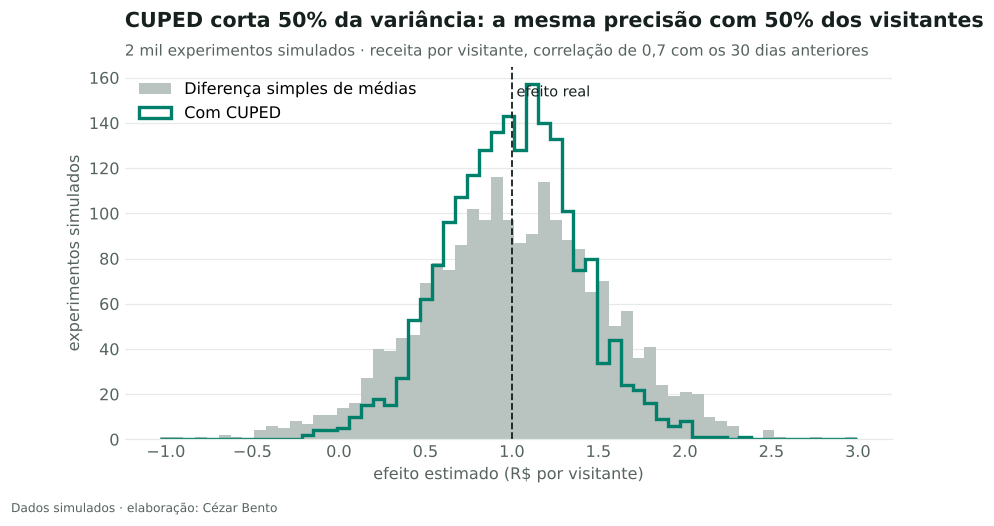

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.4))
faixa = np.linspace(min(est_simples.min(), est_cuped.min()), max(est_simples.max(), est_cuped.max()), 60)
ax.hist(est_simples, bins=faixa, color=COR["contexto"], label="Diferença simples de médias")
ax.hist(est_cuped, bins=faixa, histtype="step", lw=2.2, color=COR["principal"], label="Com CUPED")
ax.axvline(EFEITO_REAIS, color=COR["texto"], lw=1.2, ls="--")
ax.text(EFEITO_REAIS, ax.get_ylim()[1] * 0.95, " efeito real", fontsize=9.5, color=COR["texto"], va="top")
ax.set_xlabel("efeito estimado (R$ por visitante)"); ax.set_ylabel("experimentos simulados")
ax.legend(loc="upper left"); ax.grid(axis="x", visible=False)
ax.set_title(f"CUPED corta {br(reducao * 100)}% da variância: a mesma precisão com {br((1 - reducao) * 100)}% dos visitantes")
subtitulo(ax, "2 mil experimentos simulados · receita por visitante, correlação de 0,7 com os 30 dias anteriores")
fonte(fig, FONTE)
fig.savefig(FIG + "05_cuped.png")

## 6. Antes de ler o resultado: a divisão do tráfego deu certo?

Se o planejado era 50/50 e chegaram 50.000 visitantes em A e 48.800 em B, isso é variação normal ou sinal de defeito? O teste de **Sample Ratio Mismatch** (SRM) responde. Um desvio assim costuma vir de bug na atribuição, redirecionamento que perde usuários ou robôs filtrados só de um lado, e invalida a comparação.

In [12]:
for a, b in [(50_000, 49_800), (50_000, 48_800)]:
    p = verificar_srm(a, b)
    veredito = "pode seguir" if p > 0.001 else "PARE: investigue a atribuição antes de ler o resultado"
    print(f"A = {br(a)} · B = {br(b)} · diferença de {(a - b) / (a + b):.2%} → p = {p:.4f} · {veredito}")

A = 50.000 · B = 49.800 · diferença de 0.20% → p = 0.5267 · pode seguir
A = 50.000 · B = 48.800 · diferença de 1.21% → p = 0.0001 · PARE: investigue a atribuição antes de ler o resultado


O limite usual é p < 0,001, mais rígido que o do teste principal, porque a checagem roda em todo experimento e um alarme falso custaria uma investigação.

## Checklist de um teste A/B confiável

| Momento | Pergunta | Ferramenta |
|---|---|---|
| Antes | Qual a menor melhora que muda a decisão? | Efeito mínimo detectável |
| Antes | Quantos visitantes e quantos dias? | Cálculo de amostra + conferência por simulação |
| Antes | Quantas vezes vamos olhar? | Limites de O'Brien-Fleming |
| Antes | Há uma métrica anterior correlacionada? | CUPED |
| Durante | A divisão do tráfego está certa? | Teste de SRM |
| Depois | O resultado foi aberto em segmentos? | Holm ou Benjamini-Hochberg; segmento vira hipótese |
| Depois | A melhora se mantém em produção? | Grupo de controle de longo prazo (*holdout*) |

**Limitações:** a simulação assume visitantes independentes e efeito constante no tempo. Testes reais têm efeito novidade, sazonalidade de dia da semana e interferência entre usuários (por exemplo, em marketplaces), que pedem desenhos próprios.